## Author: Malambe Sebenzile Octavia


# RQ2: Do poorer EU regions grow faster?
## Absolute beta convergence across NUTS 2 regions, 2016-2024

**Project C: Are EU regions converging?**

**Research question 2.** Using 2016 GDP and annualised growth to 2024,
estimate beta convergence. Report the slope, the fit, and the sensitivity
of the result to commuter regions.


## 1. Dataset

**Source.** Eurostat regional GDP at NUTS 2 level, downloaded through
the Eurostat SDMX API and cleaned in this project (`data/processed/gdp_clean.csv`).   


**Variable used.** `gdp_pps_index`: GDP per head in purchasing power
standards (PPS), expressed as an index relative to the EU average
(EU = 100).

**Structure.** One row per region per year (a long panel).

| Column | Meaning |
|---|---|
| `region_code`, `region_name` | NUTS 2 region |
| `country_code` | Member state (used for clustering) |
| `year` | 2016 to 2024 |
| `gdp_pps_index` | GDP per head, PPS, EU = 100 (whole numbers) |
| `gdp_pps_index_flag` | Eurostat flag: `p` provisional, `e` estimated, `b` break in series |

**Coverage.** 244 regions in 27 countries, 9 years, 2,196 rows, no
missing GDP values and no duplicate region-year rows.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path
from IPython.display import Image, display

# Find the project root (works from the root or from /notebooks)
ROOT = Path(".")
if not (ROOT / "data" / "processed" / "gdp_clean.csv").exists():
    ROOT = Path("..")
OUT = ROOT / "outputs"

START = 2016
END = 2024
T = END - START
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

In [4]:
g = pd.read_csv(ROOT / "data" / "processed" / "gdp_clean.csv")

print("Rows x columns:", g.shape)
print("Regions:", g["region_code"].nunique())
print("Countries:", g["country_code"].nunique())
print("Years:", g["year"].min(), "to", g["year"].max())
print("Duplicate region-year rows:",
      g.duplicated(["region_code", "year"]).sum())
print("Missing GDP values:", g["gdp_pps_index"].isna().sum())
display(g.head())

Rows x columns: (2196, 6)
Regions: 244
Countries: 27
Years: 2016 to 2024
Duplicate region-year rows: 0
Missing GDP values: 0


,region_code,region_name,country_code,year,gdp_pps_index,gdp_pps_index_flag
0,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,BE,2016,206,NaN
1,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,BE,2017,203,NaN
2,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,BE,2018,199,NaN
3,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,BE,2019,200,NaN
4,BE10,Région de Bruxelles-Capitale/Brussels Hoofdste...,BE,2020,199,NaN


**Data-quality flags by year.** The 2024 values are the least settled:
most are provisional (`p`) or estimated (`e`). This is why the results
section tests an earlier end year (2023).

In [5]:
flag = g["gdp_pps_index_flag"].fillna("none")
display(pd.crosstab(g["year"], flag))

gdp_pps_index_flag,b,e,none,p
year,,,,
2016,0,0,231,13
2017,0,0,231,13
2018,0,0,231,13
2019,0,0,231,13
2020,17,0,214,13
2021,4,0,189,51
2022,17,0,149,78
2023,0,0,147,97
2024,0,33,69,142


In [6]:
wide = g[g["year"].isin([START, END])].pivot(
    index="region_code", columns="year", values="gdp_pps_index")
display(wide.describe().round(1))

year,2016,2024
count,244.0,244.0
mean,94.4,94.0
std,37.6,35.7
min,26.0,30.0
25%,67.0,70.8
50%,88.0,87.0
75%,115.2,110.0
max,275.0,268.0


## 2. Method

**Absolute beta convergence.** Following the standard cross-section
approach (Barro and Sala-i-Martin, 1992; Sala-i-Martin, 1996), regress
each region's annualised growth on its starting level:

$$
\frac{\ln y_{i,2024} - \ln y_{i,2016}}{T}
= \alpha + \beta \,\ln y_{i,2016} + \varepsilon_i ,
\qquad T = 8
$$

where $y_{i,t}$ is region $i$'s GDP-per-head index. A **negative
$\beta$** means that poorer regions grew faster, which is beta
convergence. The model has no control variables, so it tests *absolute*
convergence (it does not account for regional differences in structure
or institutions).

**Fit and speed.** The fit is the $R^2$ of the regression. The slope
is converted into a convergence speed $\lambda$ and a half-life (the
time to close half of the gap to the long-run level):

$$
\lambda = -\frac{\ln(1 + \beta T)}{T},
\qquad
\text{half-life} = \frac{\ln 2}{\lambda}
$$

**Inference.** Standard errors are clustered by country (27 clusters),
because regions in the same country share national shocks, and Germany
alone has 38 regions. Treating regions as independent would overstate
significance (Cameron and Miller, 2015).

**Sensitivity analysis.** The main model (A) is re-estimated under
alternative samples to see whether the answer depends on a few regions
or on data quality:

| Model | What it tests |
|---|---|
| A | Full sample (the answer to RQ2) |
| B | Excluding the commuter ring around seven capitals |
| B2 | Excluding capital cores and their commuter rings |
| C | Excluding regions with a break-in-series flag (`b`) |
| D | Excluding influential regions (Cook's distance > 4/n; Cook, 1977) |
| E | End year 2023 instead of 2024 (less provisional data) |
| F | Excluding Ireland (multinational distortion of GDP) |
| G | Excluding French overseas regions |
| H | Excluding Ireland and French overseas regions |
| I | Excluding the team outlier list (LU00, IE05, IE06, BE10) |

**Commuter-region definition.** The data has no commuter flag, so a
simple rule was used: the region containing a capital city is the
*core* and the region directly around it is the *commuter ring*.

| Country | Core | Ring |
|---|---|---|
| Belgium | BE10 (Brussels) | BE24 (Vlaams-Brabant), BE31 (Brabant wallon) |
| Germany | DE30 (Berlin) | DE40 (Brandenburg) |
| Austria | AT13 (Wien) | AT12 (Niederosterreich) |
| Czechia | CZ01 (Praha) | CZ02 (Stredni Cechy) |
| Hungary | HU11 (Budapest) | HU12 (Pest) |
| Denmark | DK01 (Hovedstaden) | DK02 (Sjaelland) |
| Ireland | IE06 (Eastern and Midland) | none (Dublin lies inside IE06) |



## 3. Code

The full, runnable analysis is in `src/12_rq2_beta_convergence.py`.
The two functions at its core are reproduced below. The cell then
re-estimates the main model (A) and checks it against the saved
results.

In [7]:
def build(df, start, end):
    # One row per region: start level, end level, annualised growth.
    sub = df[df["year"].isin([start, end])]
    wide = sub.pivot(index="region_code", columns="year",
                     values="gdp_pps_index")
    wide = wide.dropna()
    wide = wide.rename(columns={start: "y0", end: "y1"})

    meta = df.drop_duplicates("region_code").set_index("region_code")
    meta = meta[["region_name", "country_code"]]

    out = meta.join(wide, how="inner")
    out["ln_y0"] = np.log(out["y0"])
    diff = np.log(out["y1"]) - np.log(out["y0"])
    out["growth"] = diff / (end - start)
    return out


def fit(d, label, T):
    # OLS of growth on ln(start level), country-clustered errors.
    X = sm.add_constant(d["ln_y0"])
    groups = pd.factorize(d["country_code"])[0]
    m = sm.OLS(d["growth"], X).fit(
        cov_type="cluster", cov_kwds={"groups": groups})

    b = m.params["ln_y0"]
    inner = 1 + b * T
    speed = -np.log(inner) / T if inner > 0 else np.nan
    half = np.log(2) / speed if speed == speed and speed > 0 else np.nan
    return {"model": label, "n_regions": int(m.nobs), "slope": b,
            "se_cluster": m.bse["ln_y0"], "p_value": m.pvalues["ln_y0"],
            "r_squared": m.rsquared, "speed": speed,
            "half_life_yrs": half}

In [8]:
full = build(g, START, END)
modelA = fit(full, "A. Full sample", T)
nums = {k: v for k, v in modelA.items() if k != "model"}
print(pd.Series(nums).round(4).to_string())

# Consistency check against the saved script output
saved = pd.read_csv(OUT / "rq2_results.csv")
savedA = saved[saved["model"].str.startswith("A.")].iloc[0]
print()
print("Slope matches saved result:",
      abs(modelA["slope"] - savedA["slope"]) < 1e-9)

n_regions        244.0000
slope             -0.0167
se_cluster         0.0045
p_value            0.0002
r_squared          0.2371
speed              0.0179
half_life_yrs     38.7851

Slope matches saved result: True


## 4. Results

In [9]:
res = pd.read_csv(OUT / "rq2_results.csv")
show = res.copy()
for c in ["slope", "se_cluster", "r_squared", "speed"]:
    show[c] = show[c].round(4)
show["p_value"] = show["p_value"].round(4)
show["half_life_yrs"] = show["half_life_yrs"].round(1)
display(show)

,model,n_regions,slope,se_cluster,p_value,r_squared,speed,half_life_yrs
0,A. Full sample,244,-0.0167,0.0045,0.0002,0.2371,0.0179,38.8
1,B. Excl. commuter ring,237,-0.0168,0.0045,0.0002,0.2412,0.0180,38.4
2,B2. Excl. core + ring,230,-0.0191,0.0043,0.0000,0.3002,0.0207,33.4
3,C. Excl. break-flag regions,223,-0.0152,0.0051,0.0028,0.1937,0.0162,42.8
4,D. Excl. influential regions,228,-0.0182,0.0032,0.0000,0.3691,0.0196,35.3
5,E. End year 2023,244,-0.0167,0.0047,0.0004,0.2206,0.0177,39.1
6,F. Excl. Ireland,241,-0.0183,0.0042,0.0000,0.2888,0.0198,35.0
7,G. Excl. French overseas,239,-0.0176,0.0046,0.0001,0.2615,0.0189,36.6
8,H. Excl. Ireland + overseas,236,-0.0193,0.0042,0.0000,0.3181,0.0210,33.0
9,I. Excl. team outlier list,240,-0.0187,0.0043,0.0000,0.2820,0.0202,34.3


**Main result (model A, N = 244 regions).**

| Statistic | Value |
|---|---|
| Slope $\beta$ | **-0.0167** |
| Clustered standard error | 0.0045 |
| p-value | 0.0002 |
| $R^2$ | 0.24 |
| Convergence speed $\lambda$ | 1.8% per year |
| Half-life | about 39 years |

The slope is negative and statistically significant: regions that
started poorer grew faster. A region that started twice as rich as
another grew about 1.2 percentage points per year more slowly
($0.0167 \times \ln 2$).

**Sensitivity.** The slope stays between -0.015 and -0.019, and is
significant in every version.

| Model | Regions | Slope | $R^2$ | Half-life (yrs) |
|---|---|---|---|---|
| A. Full sample | 244 | -0.0167 | 0.24 | 38.8 |
| B. Excl. commuter ring | 237 | -0.0168 | 0.24 | 38.4 |
| B2. Excl. core + ring | 230 | -0.0191 | 0.30 | 33.4 |
| C. Excl. break-flag regions | 223 | -0.0152 | 0.19 | 42.8 |
| D. Excl. influential regions | 228 | -0.0182 | 0.37 | 35.3 |
| E. End year 2023 | 244 | -0.0167 | 0.22 | 39.1 |
| F. Excl. Ireland | 241 | -0.0183 | 0.29 | 35.0 |
| G. Excl. French overseas | 239 | -0.0176 | 0.26 | 36.6 |
| H. Excl. Ireland + overseas | 236 | -0.0193 | 0.32 | 33.0 |
| I. Excl. team outlier list | 240 | -0.0187 | 0.28 | 34.3 |

**Commuter-region sensitivity.** Removing the seven commuter rings
leaves the slope unchanged (-0.0167 to -0.0168). Removing the capital
cores as well steepens it to -0.0191 and raises $R^2$ to 0.30.

**Data-artefact checks.** The Greek decline (Dytiki Makedonia,
66 to 48) is a smooth multi-year fall with no break flags. The Irish
regions are volatile (IE05 rises from 195 to 270 in 2022, then falls
back to 217) and their 2024 values are flagged as estimates. The French
overseas regions are provisional from 2022.

In [10]:
reg = pd.read_csv(OUT / "rq2_region_level.csv", index_col=0)
cols = ["region_name", "y0", "y1", "growth", "resid_z"]

print("Growing fastest relative to the fitted line:")
display(reg.sort_values("resid_z", ascending=False)[cols].head(10).round(4))
print("Growing slowest relative to the fitted line:")
display(reg.sort_values("resid_z")[cols].head(10).round(4))

Growing fastest relative to the fitted line:


,region_name,y0,y1,growth,resid_z
region_code,,,,,
IE06,Eastern and Midland,201,268,0.0360,4.1414
RO32,Bucureşti-Ilfov,136,188,0.0405,3.9725
BG41,Yugozapaden,81,107,0.0348,2.7599
RO41,Sud-Vest Oltenia,42,60,0.0446,2.6624
HU11,Budapest,139,168,0.0237,2.5803
RO11,Nord-Vest,52,71,0.0389,2.4845
LT01,Sostinės regionas,110,133,0.0237,2.2541
IE05,Southern,195,217,0.0134,2.1831
HR06,Sjeverna Hrvatska,48,64,0.0360,2.1199


Growing slowest relative to the fitted line:


,region_name,y0,y1,growth,resid_z
region_code,,,,,
EL53,Dytiki Makedonia,66,48,-0.0398,-3.8531
FRY3,Guyane,52,41,-0.0297,-3.3337
EL41,Voreio Aigaio,50,42,-0.0218,-2.7181
FRY1,Guadeloupe,77,67,-0.0174,-1.7352
HU22,Nyugat-Dunántúl,75,66,-0.0160,-1.6529
DEC0,Saarland,113,95,-0.0217,-1.5583
ES64,Ciudad de Melilla,64,59,-0.0102,-1.3842
SE31,Norra Mellansverige,97,85,-0.0165,-1.3346
FRC2,Franche-Comté,82,74,-0.0128,-1.2601


**Regions where the answer does not hold.** The largest departures
from the fitted line fall into two groups.

*Grew much faster than the line predicts:* Eastern and Midland
(Ireland, 201 to 268), Bucuresti-Ilfov (136 to 188), Yugozapaden
(Sofia region), Budapest, and the Vilnius region started at or above
the EU average and pulled further ahead. Several poorer regions also
caught up faster than average (Sud-Vest Oltenia 42 to 60, Nord-Vest
52 to 71, Sjeverna Hrvatska 48 to 64).

*Fell behind despite starting poor:* Dytiki Makedonia (66 to 48),
Guyane (52 to 41), Voreio Aigaio (50 to 42), Guadeloupe (77 to 67) and
Nyugat-Dunantul (75 to 66). Saarland (113 to 95) also lost ground.

## 5. Visualisations

**Figure 1.** Each dot is a region. The black line is the
fitted convergence line. The ten regions furthest from the line are
labelled.

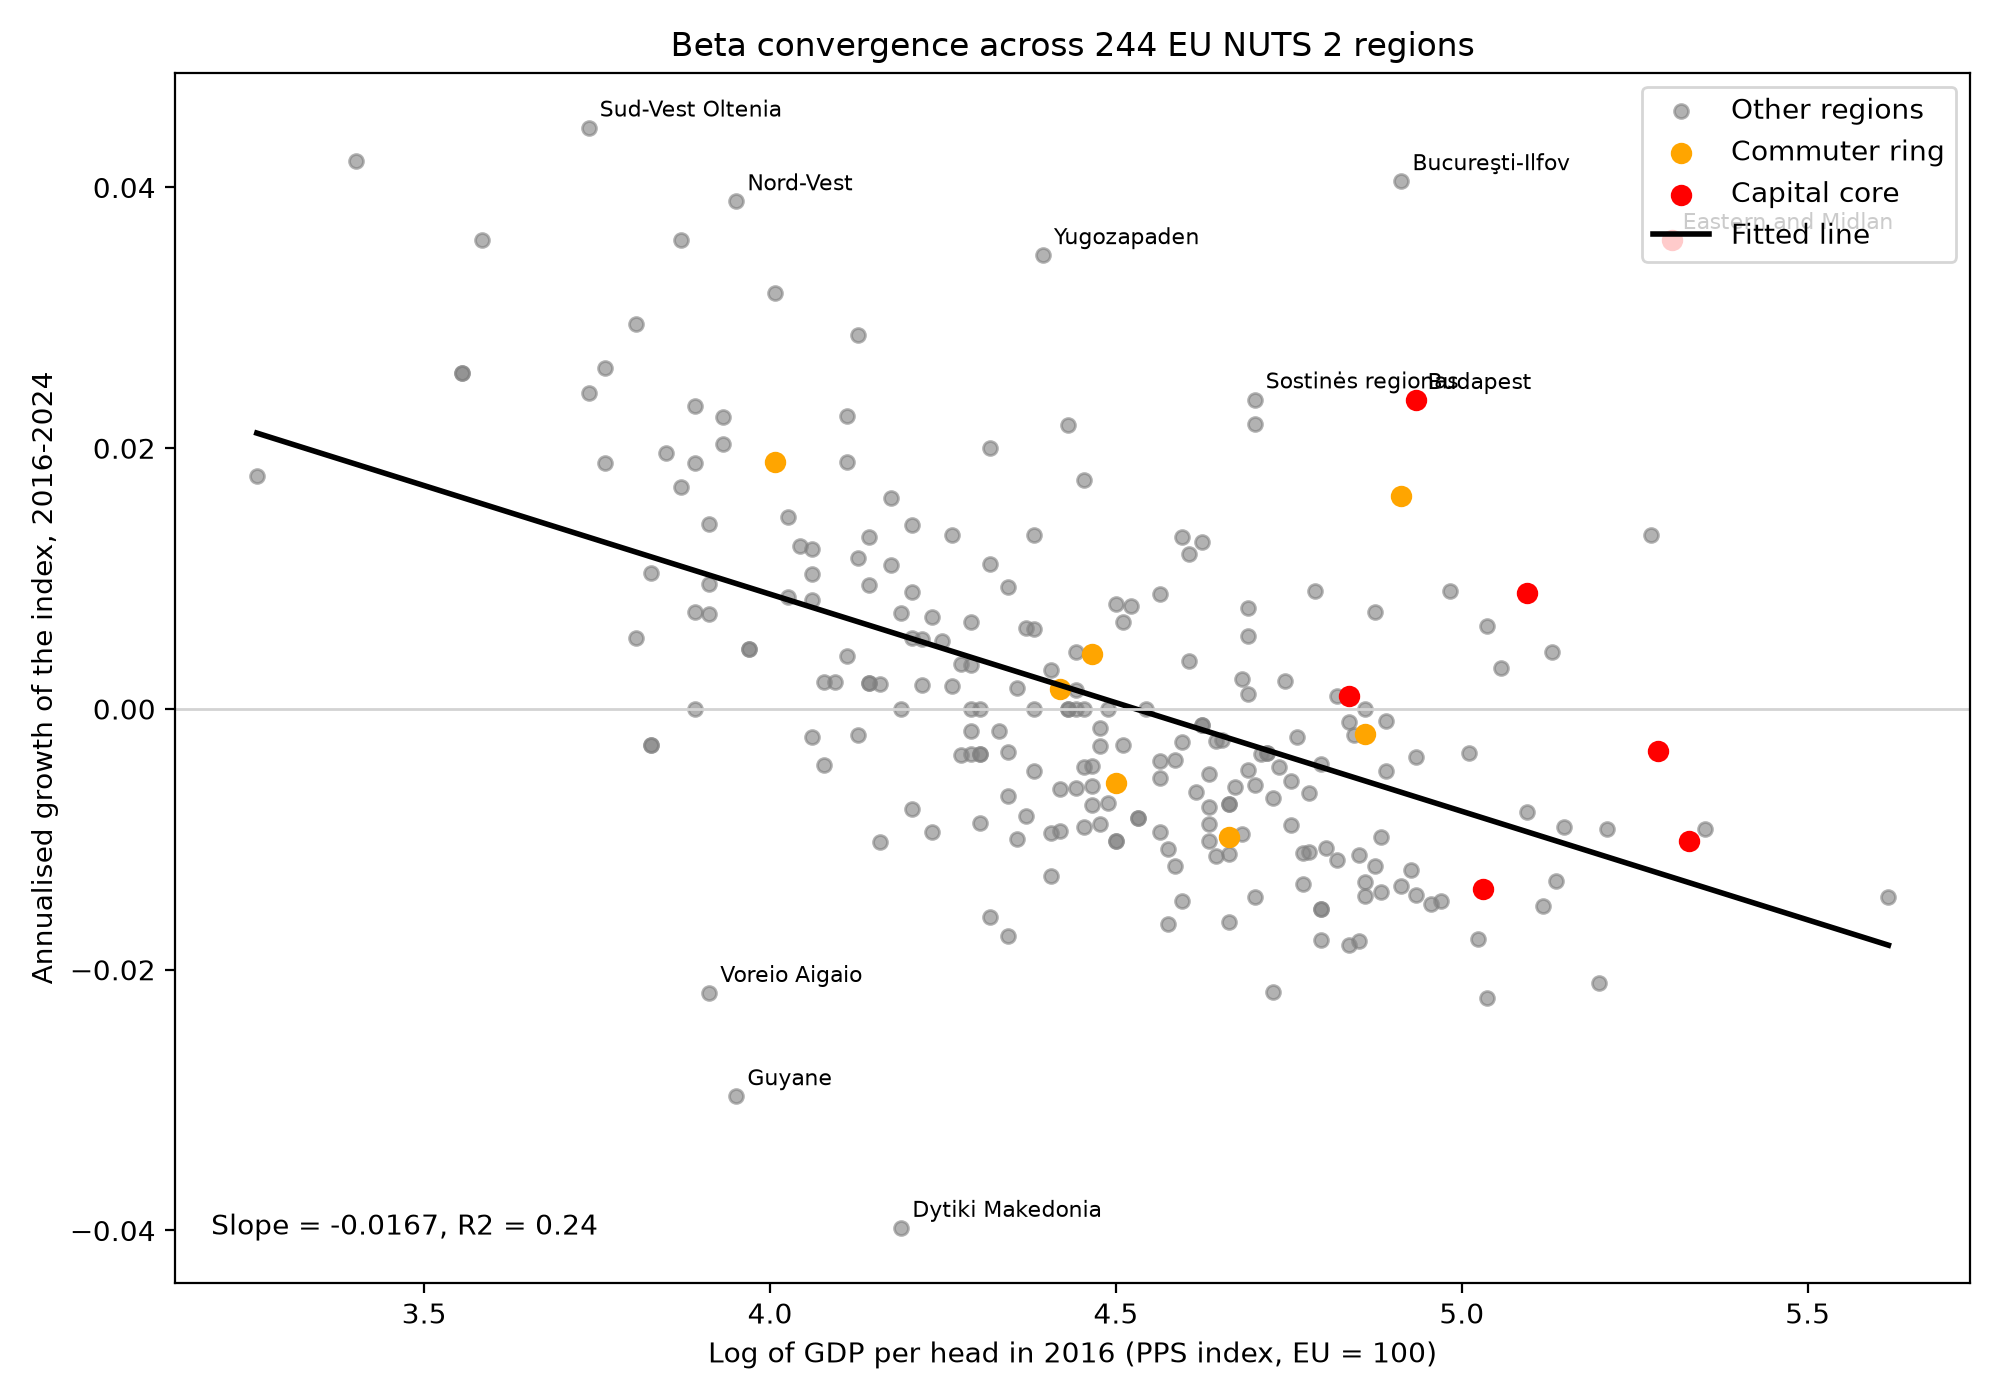

In [11]:
display(Image(filename=str(OUT / "rq2_plot1_scatter.png"), width=800))



Figure 1 shows the relationship between initial regional income and economic growth across the 244 NUTS 2 regions. The x-axis shows the log of GDP per head in 2016 (PPS index, EU = 100), while the y-axis shows the annualised growth of the index from 2016 to 2024. Each dot represents one region. Capital core regions are marked in red and their commuter rings in orange. The ten regions furthest from the fitted line are also labelled.

The fitted line has a negative slope of -0.0167, suggesting that regions with higher initial income generally experienced slower growth. In practical terms, a region that was twice as wealthy as another in 2016 grew approximately 1.2 percentage points per year more slowly. This suggests a pattern of beta convergence, where poorer regions tended to catch up with wealthier ones. However, the points are quite spread out around the fitted line. The R-squared value of 0.24 indicates that initial income explains only 24% of the differences in growth between regions.

Some regions performed quite differently from what the fitted line would predict. Eastern and Midland in Ireland and Bucuresti-Ilfov experienced much higher growth than expected given their initial income. In contrast, Dytiki Makedonia and Guyane recorded much weaker growth or even a decline. The commuter rings generally had relatively small growth rates, mostly between approximately -0.01 and 0.02, and appeared on both sides of the fitted line. Removing these regions made very little difference to the slope, which changed from -0.0167 to -0.0168. However, when the capital core regions were also excluded, the slope became steeper at -0.0191. This suggests that the capital core regions weaken the overall convergence relationship rather than drive it.

**Figure 2. Robustness.** The convergence slope with its 95% interval
(country-clustered) in every model. If every interval lies to the left
of the dashed line, convergence holds in every version.

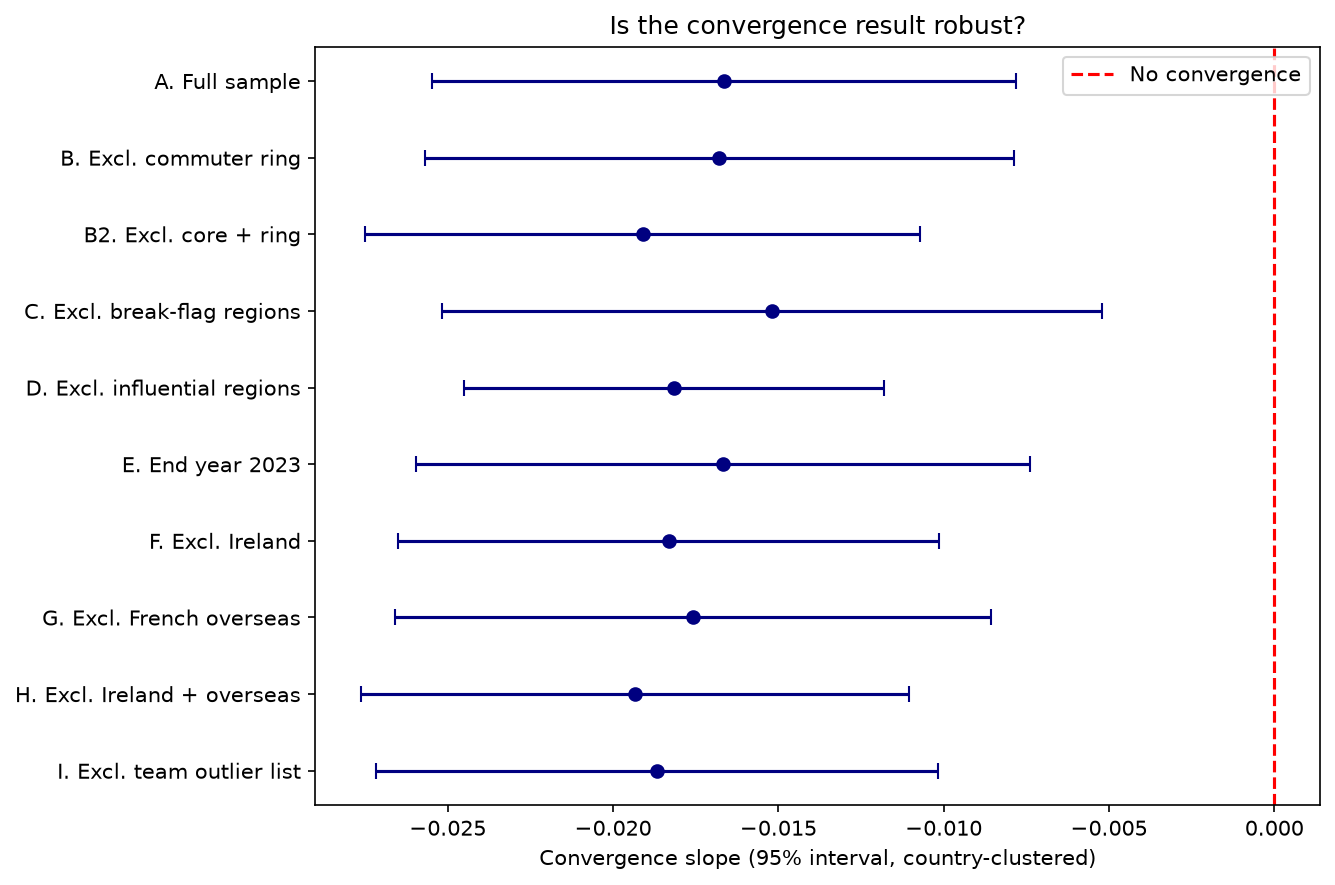

In [12]:
res = pd.read_csv(OUT / "rq2_results.csv")
labels = res["model"].tolist()
slopes = res["slope"].values
errs = 1.96 * res["se_cluster"].values
ypos = np.arange(len(res))[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(slopes, ypos, xerr=errs, fmt="o", color="navy", capsize=4)
ax.axvline(0, color="red", linestyle="--", label="No convergence")
ax.set_yticks(ypos)
ax.set_yticklabels(labels)
ax.set_xlabel("Convergence slope (95% interval, country-clustered)")
ax.set_title("Is the convergence result robust?")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "rq2_plot2_robustness.png", dpi=200)
plt.show()
plt.close("all")

Figure 2 compares the estimated convergence slopes across the ten model specifications discussed in the Method section. Each row represents a different specification. The dot shows the estimated slope, while the horizontal line represents the approximate 95% confidence interval, calculated using the slope plus or minus 1.96 clustered standard errors. Since the standard errors are clustered across only 27 countries, the confidence intervals should be interpreted with some caution. The dashed red line at zero represents the point at which there is no convergence.

The results show that all ten confidence intervals fall below zero, indicating a negative relationship between initial income and subsequent growth across all specifications. The estimated slopes range from approximately -0.015 to -0.019, and the confidence intervals overlap considerably. This suggests that the differences between the models are relatively small. Excluding wealthier or unusual regions, such as Ireland, the French overseas regions, the identified outliers, or the capital cores and commuter rings, produces slightly steeper slopes of around -0.018 to -0.019. By comparison, excluding only the commuter rings or ending the analysis in 2023 produces results close to the full-sample estimate of -0.0167. Excluding regions with a break-in-series flag (model C) produces the weakest convergence slope (-0.0152) and the widest confidence interval, although the estimate remains negative.

**Figure 3. Context: is the spread between regions narrowing?** This
is the sigma-convergence check (the standard deviation of log GDP and
the coefficient of variation by year). It links this research question to research question 4.

,sd_log,cv
year,,
2016,0.3949,0.3977
2017,0.3897,0.3951
2018,0.3846,0.3927
2019,0.3779,0.3857
2020,0.3802,0.3943
2021,0.3736,0.3969
2022,0.3705,0.3993
2023,0.3594,0.3802
2024,0.3551,0.3796


Change in SD of log: -0.101
Change in CV: -0.046


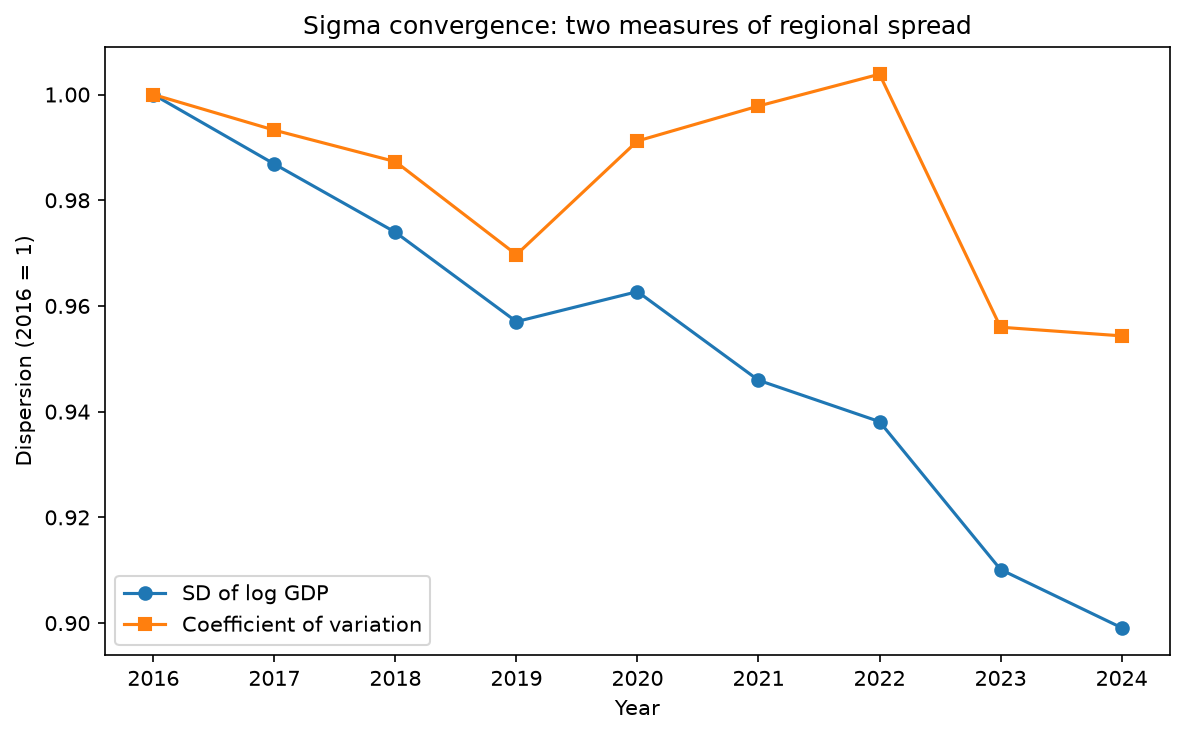

In [13]:
rows = []
for y, d in g.groupby("year"):
    s = d["gdp_pps_index"]
    rows.append({"year": y,
                 "sd_log": np.log(s).std(),
                 "cv": s.std() / s.mean()})
sig = pd.DataFrame(rows).set_index("year")
display(sig.round(4))

first, last = sig.index[0], sig.index[-1]
print("Change in SD of log:", round(sig.loc[last, "sd_log"] / sig.loc[first, "sd_log"] - 1, 3))
print("Change in CV:", round(sig.loc[last, "cv"] / sig.loc[first, "cv"] - 1, 3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sig.index, sig["sd_log"] / sig.loc[first, "sd_log"],
        marker="o", label="SD of log GDP")
ax.plot(sig.index, sig["cv"] / sig.loc[first, "cv"],
        marker="s", label="Coefficient of variation")
ax.set_xlabel("Year")
ax.set_ylabel("Dispersion (2016 = 1)")
ax.set_title("Sigma convergence: two measures of regional spread")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "rq2_plot3_sigma.png", dpi=200)
plt.show()
plt.close("all")

Figure 3 shows changes in regional income differences between 2016 and 2024 using two measures. Both are scaled to 1 in 2016, so values below 1 indicate that regional incomes have become more similar (sigma convergence). The first measure is the standard deviation of log GDP, while the second is the coefficient of variation, calculated by dividing the standard deviation by the mean.

The standard deviation of log GDP declined from 0.3949 to 0.3551, a reduction of 10.1%. There was a slight increase in 2020, from 0.3779 to 0.3802. The coefficient of variation showed a smaller decline of 4.6%, falling from 0.3977 to 0.3796. Unlike the first measure, it increased between 2019 and 2022, reaching 0.3993 before declining again. Both measures therefore suggest a reduction in regional income differences, although the extent varies depending on the measure used.

#6. Analysis

The results show evidence of beta convergence across the 244 NUTS 2 regions between 2016 and 2024. The estimated slope is -0.0167 (clustered standard error = 0.0045, p = 0.0002), indicating that regions with higher initial incomes generally experienced slower growth. A region that started twice as rich as another grew approximately 1.2 percentage points per year more slowly. The estimated convergence speed is about 1.8% per year, with a half-life of approximately 39 years. This is close to the 2% convergence rate reported by Barro and Sala-i-Martin (1992) in their study of regional growth. This suggests that, although poorer regions are catching up, the process is slow.

The model explains only 24% of the variation in regional growth (R-squared = 0.24). This means that initial income alone does not explain why some regions grew faster than others. The analysis examines absolute convergence without controlling for differences in regional characteristics. Mankiw, Romer and Weil (1992) show that convergence also depends on factors such as physical and human capital accumulation. These factors may help explain the variation observed in this study, although they were not included in the model.

Excluding the seven commuter rings makes almost no difference to the results. The slope changes slightly from -0.0167 to -0.0168, while excluding the capital cores as well produces a steeper slope of -0.0191 and reduces the half-life to approximately 33 years. This suggests that the capital regions weaken rather than drive the convergence pattern. Some capital regions, including Budapest and Eastern and Midland in Ireland, grew faster than their initial income would suggest. The findings also remain similar when Ireland, the French overseas regions, influential regions and regions with break-in-series flags are excluded, as well as when the analysis ends in 2023. Across these specifications, the slopes remain negative, ranging from approximately -0.015 to -0.019.

Overall, the findings provide evidence that poorer regions grew faster on average, but the pace of convergence was slow. The results also remain similar after excluding commuter regions. However, these rings represent only seven capital areas and were selected using a simple rule, so different ways of defining commuter regions could produce different results.

#7. References

Barro, R.J. and Sala-i-Martin, X. (1992). 'Convergence'. Journal of Political Economy, 100(2), pp. 223–251. https://doi.org/10.1086/261816.

Mankiw, N.G., Romer, D. and Weil, D.N. (1992). 'A Contribution to the Empirics of Economic Growth'. The Quarterly Journal of Economics, 107(2), pp. 407–437. https://doi.org/10.2307/2118477.